# Quan hệ giữa các nguồn dữ liệu

Notebook chứa mã phân tích theo đúng thứ tự từ các file nguồn trong `src/`. Chạy với kernel của `.venv` tại repo. Các bước có thể đọc toàn bộ raw và ghi vào `outputs/`; kiểm tra phạm vi và quy ước thời gian của từng phần trước khi diễn giải. Mã cũ dùng UTC hoặc mẫu là phương pháp cũ, chưa được coi là kết quả Moscow/toàn bộ khách hàng. Script nguồn vẫn được giữ để đối chiếu.

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
from IPython.display import display, Image, SVG, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'src/scripts'))
sys.path.insert(0, str(ROOT / 'src/mbd_mini_eda_fixes'))
def show_generated_results(started_ns, source):
    changed = sorted((p for base in (ROOT / 'outputs', ROOT / 'docs') if base.exists() for p in base.rglob('*') if p.is_file() and p.stat().st_mtime_ns >= started_ns), key=lambda p: p.as_posix())
    display(Markdown(f'### Kết quả: `{source}`'))
    if not changed:
        display(Markdown('Không có file kết quả mới từ phần này.'))
        return
    images = [p for p in changed if p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.svg')]
    png_stems = {p.with_suffix('') for p in images if p.suffix.lower() == '.png'}
    for p in images:
        if p.suffix.lower() == '.svg' and p.with_suffix('') in png_stems:
            continue
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}**'))
        display(SVG(filename=str(p)) if p.suffix.lower() == '.svg' else Image(filename=str(p)))
    tables = [p for p in changed if p.suffix.lower() == '.csv']
    for p in tables:
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}** — 5 dòng đầu'))
        try:
            display(pd.read_csv(p, nrows=5))
        except Exception as exc:
            display(Markdown(f'Không đọc được bảng: `{type(exc).__name__}: {exc}`'))
    others = [p.relative_to(ROOT).as_posix() for p in changed if p not in images and p not in tables]
    if others:
        display(Markdown('File kết quả khác: ' + ', '.join(f'`{p}`' for p in others)))

## Analyze Cross Table Relationships

Nguồn: `src/scripts/analyze_cross_table_relationships.py`. Chạy các ô của phần này theo thứ tự.

In [2]:
__file__ = str(ROOT / 'src/scripts/analyze_cross_table_relationships.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [3]:
"""Reproducible descriptive EDA; raw timestamps assumed UTC, calendar Moscow.

No model fits or top-K claims. Three prespecified independent-customer snapshots;
all available history strictly before each cutoff, common H1/H2/H3 cohort.
"""
from pathlib import Path
import json
import itertools
import hashlib
import numpy as np
import pandas as pd
import duckdb
from scipy.stats import spearmanr
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT = Path(__file__).resolve().parents[2]
OUT = ROOT / 'outputs/relationships_moscow_20261118'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
CUTOFFS = ['2022-02-01', '2022-06-01', '2022-11-01']


def markdown_table(frame):
    rows = ['| ' + ' | '.join(map(str, frame.columns)) + ' |',
            '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |']
    rows.extend('| ' + ' | '.join(str(v) for v in row) + ' |' for row in frame.itertuples(index=False, name=None))
    return '\n'.join(rows)


def wilson(k, n):
    p = k / n
    z = 1.95996398454
    center = (p + z*z/(2*n))/(1+z*z/n)
    half = z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n)
    return center-half, center+half


def save(fig, name, subtitle):
    fig.text(.01, .01, subtitle, fontsize=8, color='#475569')
    fig.tight_layout(rect=(0, .045, 1, .97))
    for ext in ['png', 'svg']:
        fig.savefig(OUT / f'{name}.{ext}', bbox_inches='tight')
    plt.close(fig)


def build():
    c = duckdb.connect()
    c.execute("SET memory_limit='3GB'")
    c.execute('SET threads=2')
    c.execute(f"SET temp_directory='{OUT.as_posix()}/tmp'")
    c.execute('SET preserve_insertion_order=false')
    c.execute('CREATE TEMP TABLE cuts(mon DATE, cutoff TIMESTAMP)')
    for day in CUTOFFS:
        cutoff = pd.Timestamp(day, tz='Europe/Moscow').tz_convert('UTC').tz_localize(None)
        c.execute('INSERT INTO cuts VALUES (?,?)', [day, cutoff.to_pydatetime()])
    c.execute(f"CREATE TEMP TABLE labels AS SELECT client_id,date_trunc('month',cast(mon AS DATE))::DATE mon,target_1,target_2,target_3,target_4,greatest(target_1,target_2,target_3,target_4) y FROM read_parquet('{ROOT.as_posix()}/data/MBD-mini/targets/**/*.parquet')")
    assert c.execute('SELECT count(*) FROM (SELECT client_id,mon,count(*) n FROM labels GROUP BY 1,2 HAVING n<>1)').fetchone()[0] == 0
    assert c.execute('SELECT count(*) FROM labels WHERE target_1 IS NULL OR target_2 IS NULL OR target_3 IS NULL OR target_4 IS NULL').fetchone()[0] == 0
    ids = c.execute(f"SELECT client_id FROM read_parquet('{ROOT.as_posix()}/data/MBD-mini/client_split/**/*.parquet')").df()
    assert ids.client_id.is_unique
    frames=[]
    for day in CUTOFFS:
        lab=c.execute('''SELECT a.client_id,a.y y_1,greatest(a.y,b.y) y_2,greatest(a.y,b.y,d.y) y_3,
            a.target_1,a.target_2,a.target_3,a.target_4 FROM labels a
            JOIN labels b ON a.client_id=b.client_id AND b.mon=a.mon+INTERVAL '1 month'
            JOIN labels d ON a.client_id=d.client_id AND d.mon=a.mon+INTERVAL '2 months'
            WHERE a.mon=CAST(? AS DATE)''',[day]).df()
        assert len(lab)==len(ids)
        frames.append(ids.merge(lab,on='client_id',validate='one_to_one').assign(mon=day))
    d=pd.concat(frames,ignore_index=True)
    expressions={
        'trx': "count(*) trx_events,count(distinct cast(event_time+INTERVAL '3 hours' AS DATE)) trx_days,count(distinct event_type) trx_types,sum(amount) FILTER(WHERE currency=11) amount11_sum,avg(amount) FILTER(WHERE currency=11) amount11_mean,count(*) FILTER(WHERE currency IS NOT NULL AND currency<>11)::DOUBLE/count(*) foreign_share",
        'geo': "count(*) geo_events,count(distinct cast(event_time+INTERVAL '3 hours' AS DATE)) geo_days,count(distinct geohash_4) geo_cells",
        'dialog': "count(*) dialog_events,count(distinct cast(event_time+INTERVAL '3 hours' AS DATE)) dialog_days,avg(sqrt(list_sum(list_transform(embedding,lambda x: x*x)))) dialog_norm"
    }
    for source,expr in expressions.items():
        print(f'Scanning full raw history: {source}',flush=True)
        path=f'{ROOT.as_posix()}/data/MBD-mini/detail/{source}/**/*.parquet'
        a=c.execute(f'''SELECT client_id,cuts.mon::VARCHAR mon,{expr},
             epoch(cuts.cutoff-max(event_time))/86400 {source}_recency,
             max(event_time) {source}_last_event
             FROM read_parquet('{path}') JOIN cuts ON event_time<cuts.cutoff
             GROUP BY client_id,cuts.mon,cuts.cutoff''').df()
        d=d.merge(a,on=['client_id','mon'],how='left',validate='one_to_one')
        for name in [source+'_events',source+'_days'] + ({'trx':['trx_types'],'geo':['geo_cells'],'dialog':[]}[source]):
            d[name]=d[name].fillna(0).astype('int64')
        print(f'{source}: {len(a):,} customer-cutoff records',flush=True)
    for source in expressions:
        cutoff=pd.to_datetime(d.mon).dt.tz_localize('Europe/Moscow').dt.tz_convert('UTC').dt.tz_localize(None)
        assert ((d[source+'_last_event']<cutoff)|d[source+'_last_event'].isna()).all()
    assert not d.duplicated(['client_id','mon']).any()
    assert (d.y_1<=d.y_2).all() and (d.y_2<=d.y_3).all()
    d.to_parquet(OUT/'customer_snapshots.parquet',index=False)
    # Associations within the actual same raw TRX row; codes treated categorically.
    tab=c.execute(f"SELECT event_type,currency,count(*) n FROM read_parquet('{ROOT.as_posix()}/data/MBD-mini/detail/trx/**/*.parquet') GROUP BY 1,2").df()
    tab.to_csv(OUT/'raw_trx_type_currency.csv',index=False)
    return d, tab

In [4]:
def analyze(d,tab):
    features=['trx_events','trx_days','trx_types','amount11_sum','amount11_mean','foreign_share','trx_recency','geo_events','geo_days','geo_cells','geo_recency','dialog_events','dialog_days','dialog_recency','dialog_norm']
    names=['TRX events','TRX active days','TRX types','Amount sum (11)','Amount mean (11)','Foreign-code share','TRX recency','GEO events','GEO active days','GEO cells g4','GEO recency','Dialog events','Dialog active days','Dialog recency','Embedding norm']
    pairs=[]
    for mon,g in d.groupby('mon'):
        for a,b in itertools.combinations(features,2):
            valid=g[[a,b]].dropna()
            rho=float(spearmanr(valid[a],valid[b]).statistic) if len(valid)>2 and valid[a].nunique()>1 and valid[b].nunique()>1 else np.nan
            pairs.append(dict(mon=mon,a=a,b=b,n=len(valid),rho=rho))
    pd.DataFrame(pairs).to_csv(OUT/'spearman_pairs.csv',index=False)
    last=d[d.mon==CUTOFFS[-1]].copy()
    active_pairs=[]
    for a,b in [('trx_events','geo_events'),('trx_events','dialog_events'),('geo_events','dialog_events'),('trx_events','amount11_sum'),('trx_events','amount11_mean')]:
        v=last[[a,b]].dropna()
        v=v[(v[a]>0)&(v[b]>0)]
        active_pairs.append(dict(a=a,b=b,n=len(v),rho=float(spearmanr(v[a],v[b]).statistic)))
    pd.DataFrame(active_pairs).to_csv(OUT/'positive_observed_pair_correlations.csv',index=False)
    matrix=last[features].corr(method='spearman')
    matrix.to_csv(OUT/'spearman_last_cutoff.csv')
    fig,ax=plt.subplots(figsize=(12,10))
    im=ax.imshow(np.ma.masked_invalid(matrix),vmin=-1,vmax=1,cmap='RdBu_r')
    ax.set_xticks(range(len(names)),names,rotation=65,ha='right');ax.set_yticks(range(len(names)),names)
    for i in range(len(names)):
        for j in range(len(names)):
            if np.isfinite(matrix.iloc[i,j]): ax.text(j,i,f'{matrix.iloc[i,j]:.2f}',ha='center',va='center',fontsize=6)
    fig.colorbar(im,ax=ax,label='Spearman rho');ax.set_title('Within-source and cross-table relationships | cutoff Nov 2022')
    save(fig,'01_feature_correlations','One row/customer; full history before Moscow cutoff. Pairwise valid n in CSV; missing is not zero. Codes are categorical.')
    records=[]
    selected=['trx_events','amount11_sum','amount11_mean','geo_events','geo_cells','dialog_events','trx_recency','dialog_recency','dialog_norm']
    for mon,g in d.groupby('mon'):
        for h in [1,2,3]:
            for feat in selected:
                v=g[[feat,f'y_{h}']].dropna()
                rho=spearmanr(v[feat],v[f'y_{h}']).statistic
                records.append(dict(mon=mon,horizon=h,feature=feat,n=len(v),rho=rho))
    assoc=pd.DataFrame(records);assoc.to_csv(OUT/'feature_label_associations.csv',index=False)
    fig,axes=plt.subplots(1,3,figsize=(15,6),sharey=True)
    for ax,h in zip(axes,[1,2,3]):
        a=assoc[assoc.horizon==h].pivot(index='feature',columns='mon',values='rho').reindex(selected)
        im=ax.imshow(a,vmin=-.15,vmax=.15,cmap='RdBu_r',aspect='auto')
        ax.set_xticks(range(3),['Feb','Jun','Nov']);ax.set_yticks(range(len(selected)),[names[features.index(x)] for x in selected]);ax.set_title(f'Horizon {h} month(s)')
        for i in range(len(selected)):
            for j in range(3): ax.text(j,i,f'{a.iloc[i,j]:.3f}',ha='center',va='center',fontsize=8)
    fig.suptitle('Feature–purchase association across three cutoffs | Spearman rho')
    save(fig,'02_feature_label_stability','Same customers and cutoff set for H1/H2/H3. Each panel uses one row/customer/cutoff; descriptive, no causal or predictive claim.')
    rates=[]
    for feat in ['trx_events','amount11_sum','geo_events','dialog_events']:
        vals=last[feat];positive=vals.notna() & vals.gt(0)
        groups=pd.Series('No observed value',index=last.index)
        if positive.any():
            bins,edges=pd.qcut(vals[positive],4,duplicates='drop',retbins=True)
            groups.loc[positive]=['Q'+str(i+1) for i in bins.cat.codes]
            pd.DataFrame({'edge':edges}).to_csv(OUT/f'edges_{feat}.csv',index=False)
        for h in [1,2,3]:
            for group,g in last.groupby(groups):
                n=len(g);buyers=int(g[f'y_{h}'].sum());lo,hi=wilson(buyers,n)
                rates.append(dict(feature=feat,group=group,horizon=h,n=n,buyers=buyers,rate=buyers/n,low=lo,high=hi,lift=(buyers/n)/last[f'y_{h}'].mean()))
    rates=pd.DataFrame(rates);rates.to_csv(OUT/'feature_group_purchase_rates.csv',index=False)
    fig,axes=plt.subplots(2,2,figsize=(13,9))
    for ax,feat in zip(axes.flat,['trx_events','amount11_sum','geo_events','dialog_events']):
        order=['No observed value']+sorted(x for x in rates[rates.feature==feat].group.unique() if x!='No observed value')
        for h,color in zip([1,2,3],['#2563eb','#0d9488','#d97706']):
            a=rates[(rates.feature==feat)&(rates.horizon==h)].set_index('group').reindex(order).dropna(subset=['rate'])
            x=np.array([order.index(v) for v in a.index])+(h-2)*.12
            ax.errorbar(x,a.rate,yerr=[a.rate-a.low,a.high-a.rate],fmt='o-',capsize=3,label=f'H{h}',color=color)
        ax.set_xticks(range(len(order)),['No log/value' if x=='No observed value' else x for x in order],rotation=15);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_title(names[features.index(feat)]);ax.legend()
    fig.suptitle('Purchase rate by feature-only quartiles | Nov 2022 cutoff')
    save(fig,'03_feature_groups_purchase','Wilson 95% CI; Q1→Q4 among positive values, ties retained (some features have fewer groups). All prior history; raw rate, not adjusted.')
    last['source_group']=np.where(last.trx_events.gt(0),'T','-')+np.where(last.geo_events.gt(0),'G','-')+np.where(last.dialog_events.gt(0),'D','-')
    src=[]
    for group,g in last.groupby('source_group'):
        for h in [1,2,3]:
            n=len(g);k=int(g[f'y_{h}'].sum());lo,hi=wilson(k,n)
            src.append(dict(group=group,horizon=h,n=n,buyers=k,rate=k/n,low=lo,high=hi,share=n/len(last)))
    src=pd.DataFrame(src);src.to_csv(OUT/'source_combination_purchase.csv',index=False)
    order=src[src.horizon==1].sort_values('n',ascending=False).group.tolist()
    fig,axes=plt.subplots(1,2,figsize=(14,5))
    a=src[src.horizon==1].set_index('group').reindex(order)
    axes[0].bar(order,a.n,color='#475569');axes[0].set_ylabel('Customers');axes[0].set_title('Population by observed source combination')
    for h in [1,2,3]:
        a=src[src.horizon==h].set_index('group').reindex(order)
        axes[1].errorbar(range(len(order)),a.rate,yerr=[a.rate-a.low,a.high-a.rate],fmt='o-',capsize=3,label=f'H{h}')
    axes[1].set_xticks(range(len(order)),order);axes[1].yaxis.set_major_formatter(PercentFormatter(1));axes[1].legend();axes[1].set_title('Purchase rate and Wilson 95% CI')
    save(fig,'04_sources_purchase','T=TRX, G=GEO, D=Dialog, -=no observed history. Nov cutoff; full history. Unadjusted differences; small groups have wide intervals.')
    # No numerical correlation of anonymous category codes.
    top=tab.groupby('event_type')['n'].sum().nlargest(10).index
    t=tab[tab.event_type.isin(top)].copy();t['currency_group']=np.where(t.currency.isna(),'Missing',np.where(t.currency.eq(11).fillna(False),'Code 11','Other codes'))
    pivot=t.pivot_table(index='event_type',columns='currency_group',values='n',aggfunc='sum',fill_value=0).reindex(top)
    frac=pivot.div(pivot.sum(axis=1),axis=0);frac.to_csv(OUT/'trx_type_currency_shares.csv')
    fig,axes=plt.subplots(1,2,figsize=(13,6));pivot.sum(axis=1).plot.barh(ax=axes[0],color='#2563eb');axes[0].set_xlabel('Raw events');axes[0].set_title('Top 10 event_type codes by count')
    other=1-frac.get('Code 11',pd.Series(0,index=frac.index))
    axes[1].barh([str(x) for x in other.index],other,color='#0d9488');axes[1].xaxis.set_major_formatter(PercentFormatter(1));axes[1].set_title('Share with currency other than 11 or missing')
    save(fig,'05_trx_categories_currency','All raw TRX rows; categorical comparison, no Pearson correlation of codes. Missing currency separately available in CSV. Not a currency-name mapping.')
    # Full period multilabel association uses unique customer-month, not event rows.
    c=duckdb.connect()
    labels=c.execute(f"SELECT client_id,mon,target_1,target_2,target_3,target_4 FROM read_parquet('{ROOT.as_posix()}/data/MBD-mini/targets/**/*.parquet')").df()
    cols=['target_1','target_2','target_3','target_4'];co=labels[cols].corr();co.to_csv(OUT/'label_phi.csv')
    joint=labels[cols].T.dot(labels[cols]);joint.to_csv(OUT/'label_joint_positive_counts.csv')
    fig,axes=plt.subplots(1,2,figsize=(11,5))
    for ax,m,title,fmt in [(axes[0],co,'Same-month label association (phi)','.3f'),(axes[1],joint,'Joint positive customer-months',',.0f')]:
        im=ax.imshow(m,cmap='Blues');ax.set_xticks(range(4),cols,rotation=20);ax.set_yticks(range(4),cols);ax.set_title(title)
        for i in range(4):
            for j in range(4):ax.text(j,i,format(m.iloc[i,j],fmt),ha='center',va='center')
    save(fig,'06_product_cooccurrence','All 12 label months; phi is Pearson for binary labels. Descriptive pooled counts; repeated customers mean rows are not independent.')
    insights=[]
    pp=pd.DataFrame(pairs);strong=pp[pp.mon==CUTOFFS[-1]].assign(abs_rho=lambda x:x.rho.abs()).sort_values('abs_rho',ascending=False)
    insights.append('# EDA relationships — executed on raw data\n')
    insights.append('Moscow cutoffs: Feb/Jun/Nov 2022; full prior history. Raw naive timestamps assumed UTC, converted without changing instants. Same population with complete H1/H2/H3 labels. No model fit, horizon selection or top-K performance claim.\n')
    insights.append('## Strongest numerical relationships at Nov cutoff\n'+markdown_table(strong.head(15).drop(columns='abs_rho')))
    insights.append('## Feature–label association\n'+markdown_table(assoc[assoc.mon==CUTOFFS[-1]]))
    insights.append('## Feature-group purchase rates\n'+markdown_table(rates))
    insights.append('## Source combinations\n'+markdown_table(src))
    insights.append('## Interpretation limits\nCorrelations are observational. Counts/days, sums/counts and cell diversity/counts are partly mechanically related. Zero counts mean no observed event, not inactivity. Amount sums only code 11; no named currency or revenue inference. Embedding norm is not meaning or sentiment. Quartiles describe the same cohort, not predictive validation. Wilson intervals are per group/cutoff; no pooled independent-row CI or multiple-testing significance claim. Cutoffs are prespecified representative snapshots, not every month. All figures include all customers where defined, with unknown values retained outside numeric pairwise correlations.\n')
    (OUT/'REPORT.md').write_text('\n\n'.join(insights),encoding='utf-8')
    checks={'unique_customer_cutoff':not d.duplicated(['client_id','mon']).any(),'same_cohort_all_cutoffs':all(set(g.client_id)==set(last.client_id) for _,g in d.groupby('mon')),'nested_horizons':bool(((d.y_1<=d.y_2)&(d.y_2<=d.y_3)).all()),'group_population_reconciles':all(g.n.sum()==len(last) for _,g in rates.groupby(['feature','horizon'])),'source_population_reconciles':all(g.n.sum()==len(last) for _,g in src.groupby('horizon')),'six_figures':len(list(OUT.glob('*.png')))==6}
    assert all(checks.values()),checks
    (OUT/'validation.json').write_text(json.dumps(checks,indent=2),encoding='utf-8')
    manifest={'cutoffs_moscow':CUTOFFS,'history':'all available event_time < cutoff','raw_naive_assumption':'UTC','horizons':[1,2,3],'snapshot_rows':len(d),'customers_per_cutoff':len(last),'script_sha256':hashlib.sha256(Path(__file__).read_bytes()).hexdigest(),'figures':[p.name for p in sorted(OUT.glob('*.png'))]}
    (OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
    print(json.dumps(manifest,indent=2),flush=True)

In [5]:
if __name__=='__main__':
    frame, contingency=build()
    analyze(frame,contingency)

Scanning full raw history: trx


trx: 274,792 customer-cutoff records


Scanning full raw history: geo


geo: 197,760 customer-cutoff records


Scanning full raw history: dialog


dialog: 107,936 customer-cutoff records


{
  "cutoffs_moscow": [
    "2022-02-01",
    "2022-06-01",
    "2022-11-01"
  ],
  "history": "all available event_time < cutoff",
  "raw_naive_assumption": "UTC",
  "horizons": [
    1,
    2,
    3
  ],
  "snapshot_rows": 300672,
  "customers_per_cutoff": 100224,
  "script_sha256": "59136740f6d9ce8d50a324c3e3dc2224e46065834bc67af9e97ace786d4c1259",
  "figures": [
    "01_feature_correlations.png",
    "02_feature_label_stability.png",
    "03_feature_groups_purchase.png",
    "04_sources_purchase.png",
    "05_trx_categories_currency.png",
    "06_product_cooccurrence.png"
  ]
}


### Kết quả: `src/scripts/analyze_cross_table_relationships.py`

**outputs/relationships_moscow_20261118/01_feature_correlations.png**

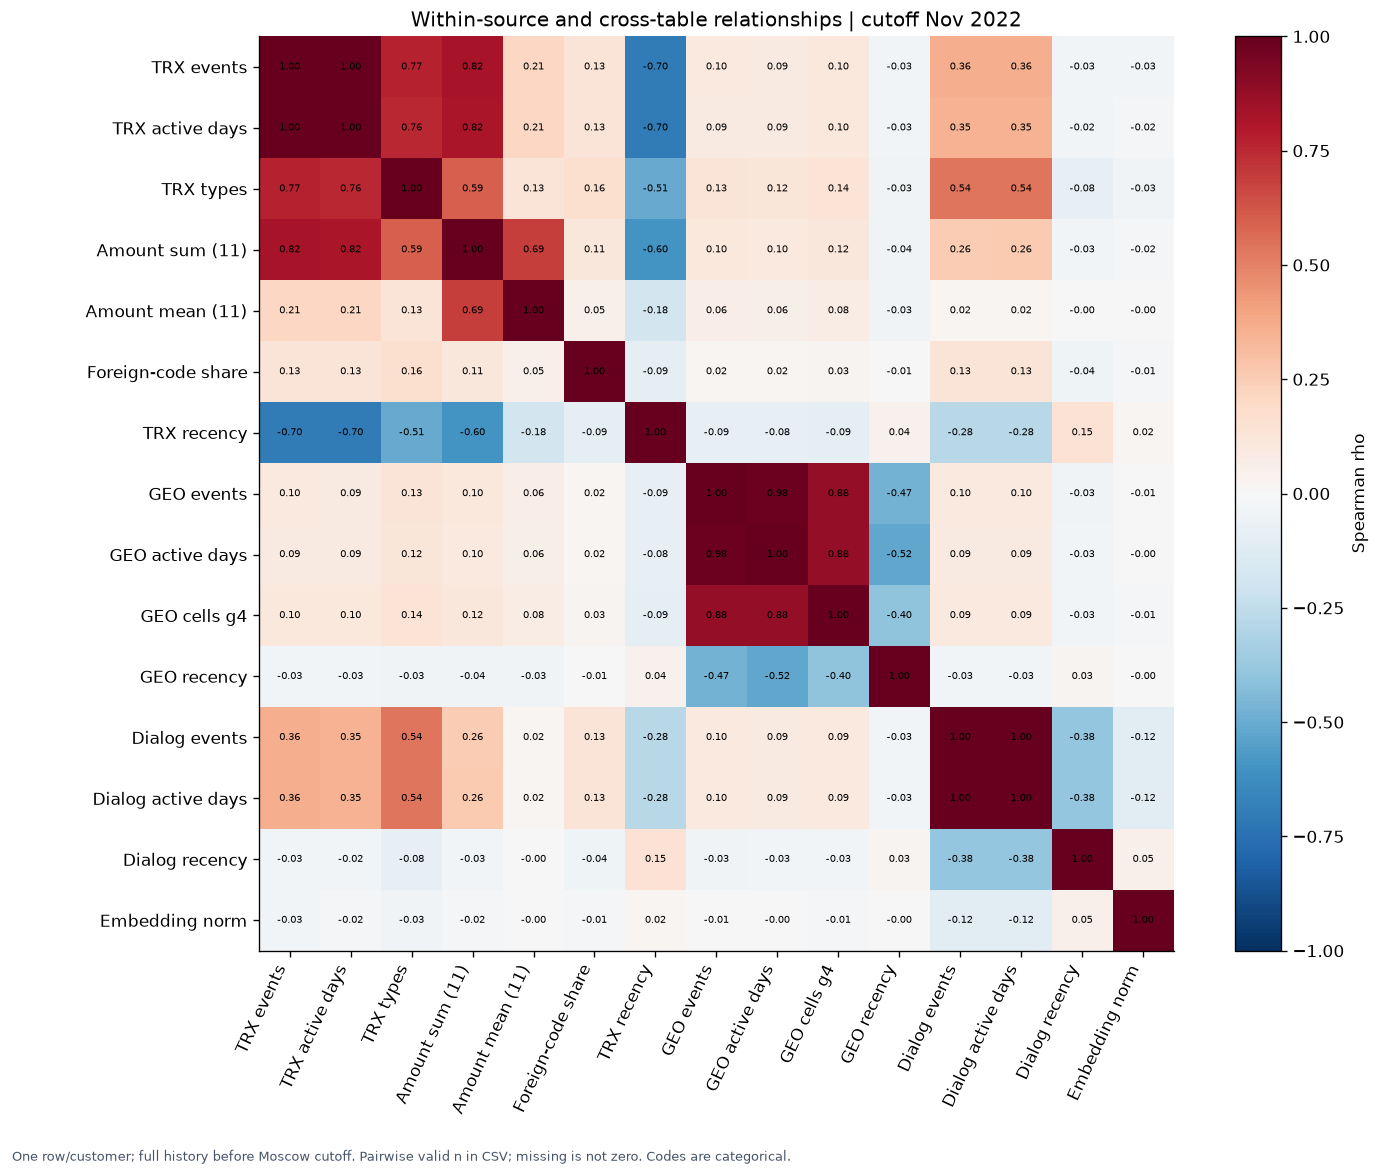

**outputs/relationships_moscow_20261118/02_feature_label_stability.png**

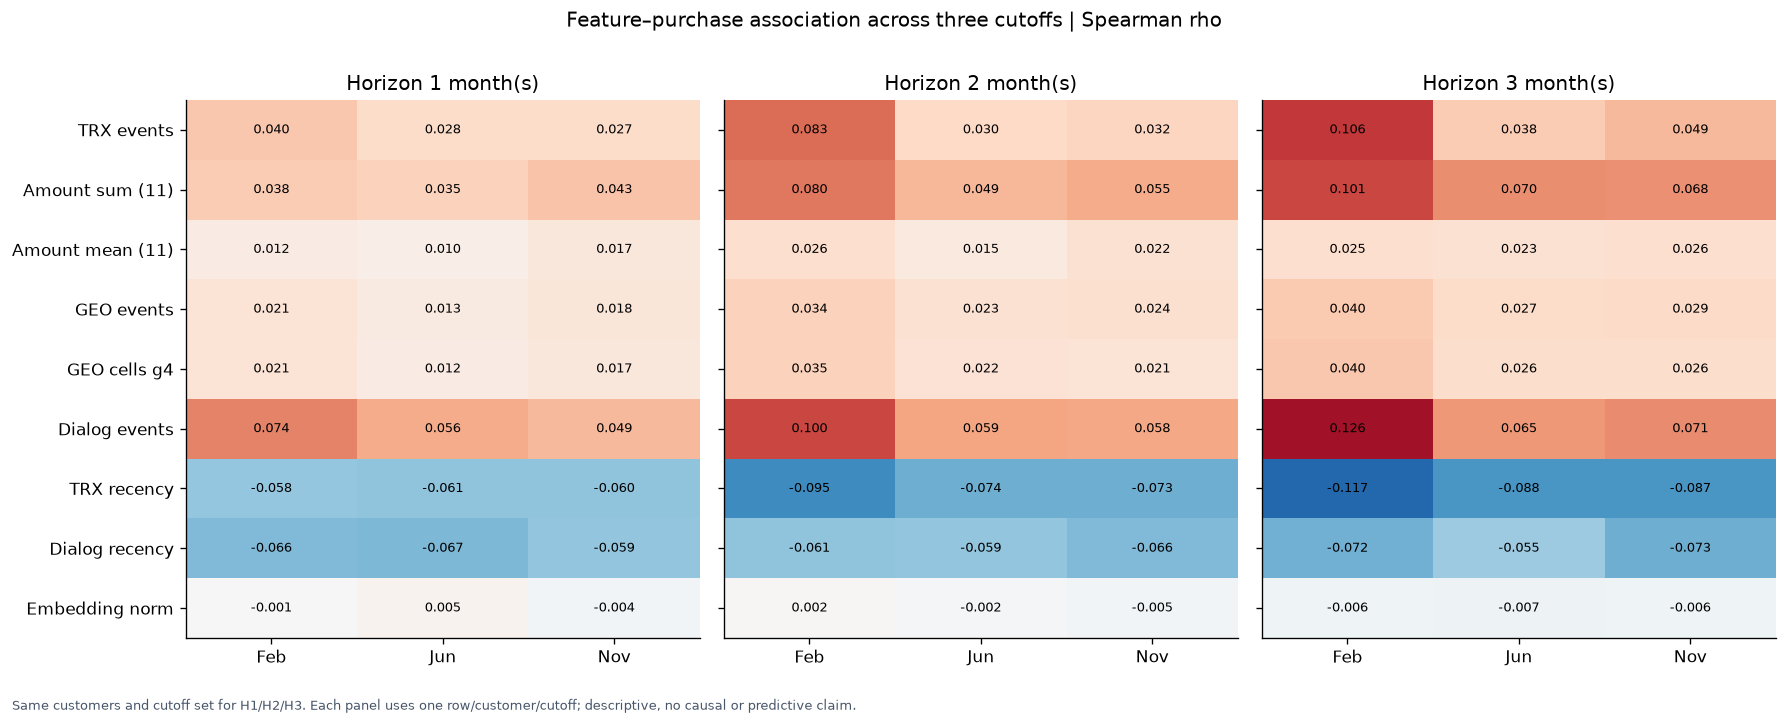

**outputs/relationships_moscow_20261118/03_feature_groups_purchase.png**

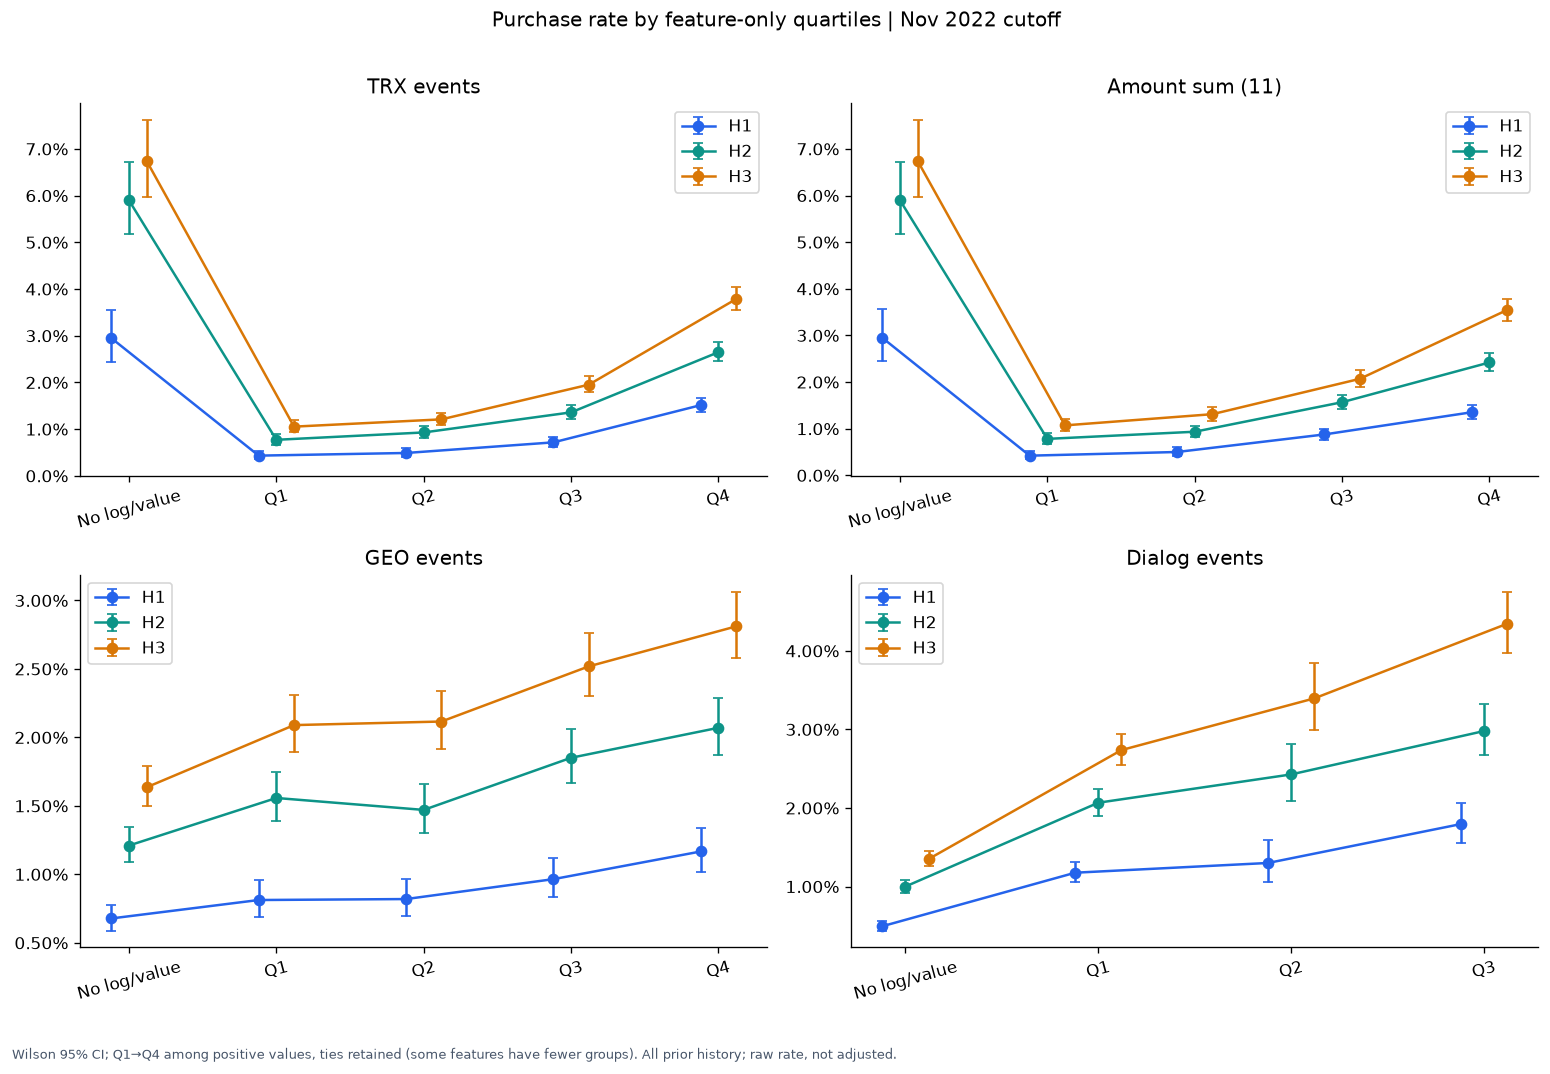

**outputs/relationships_moscow_20261118/04_sources_purchase.png**

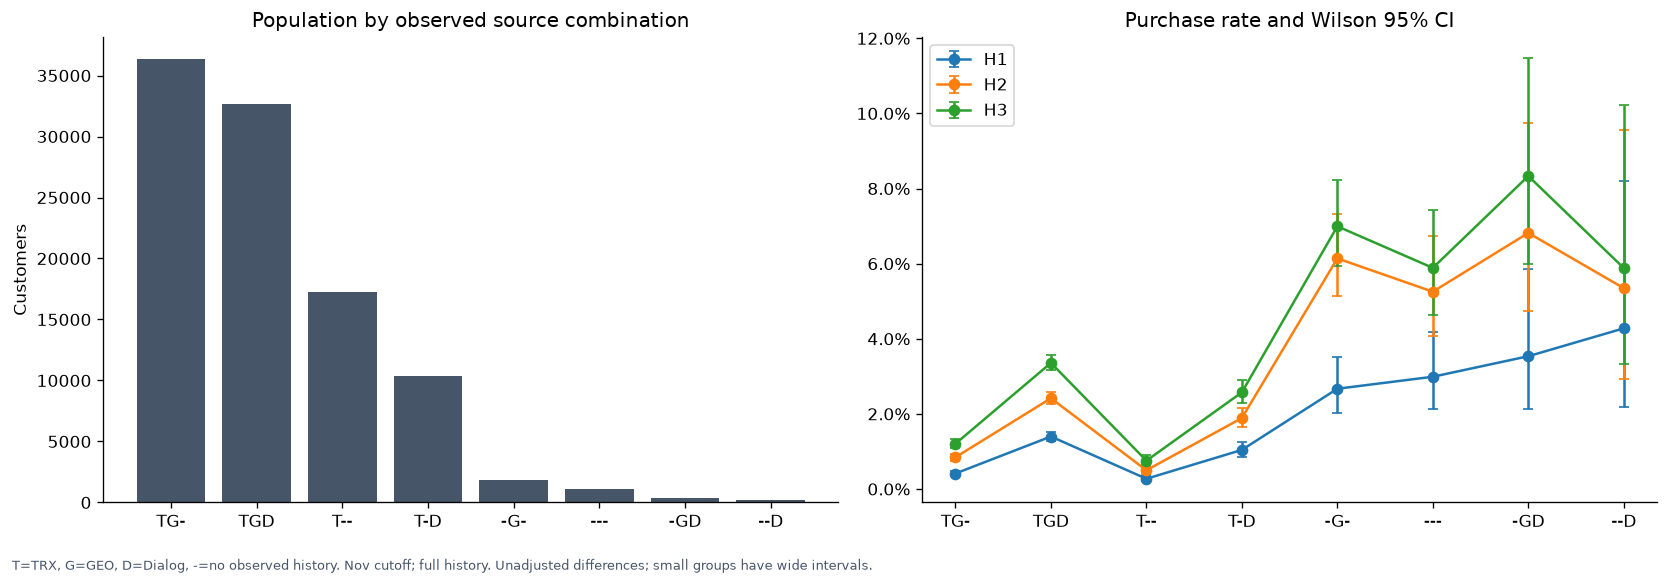

**outputs/relationships_moscow_20261118/05_trx_categories_currency.png**

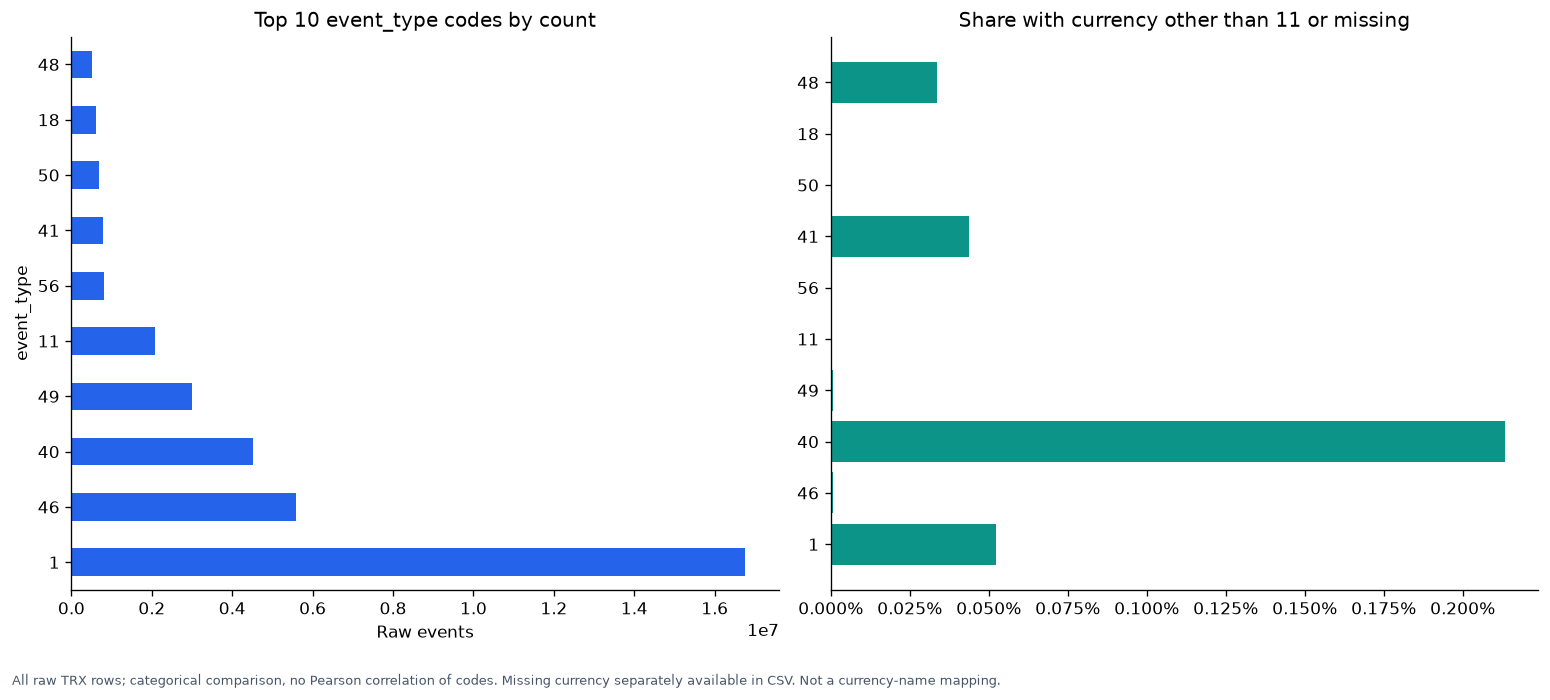

**outputs/relationships_moscow_20261118/06_product_cooccurrence.png**

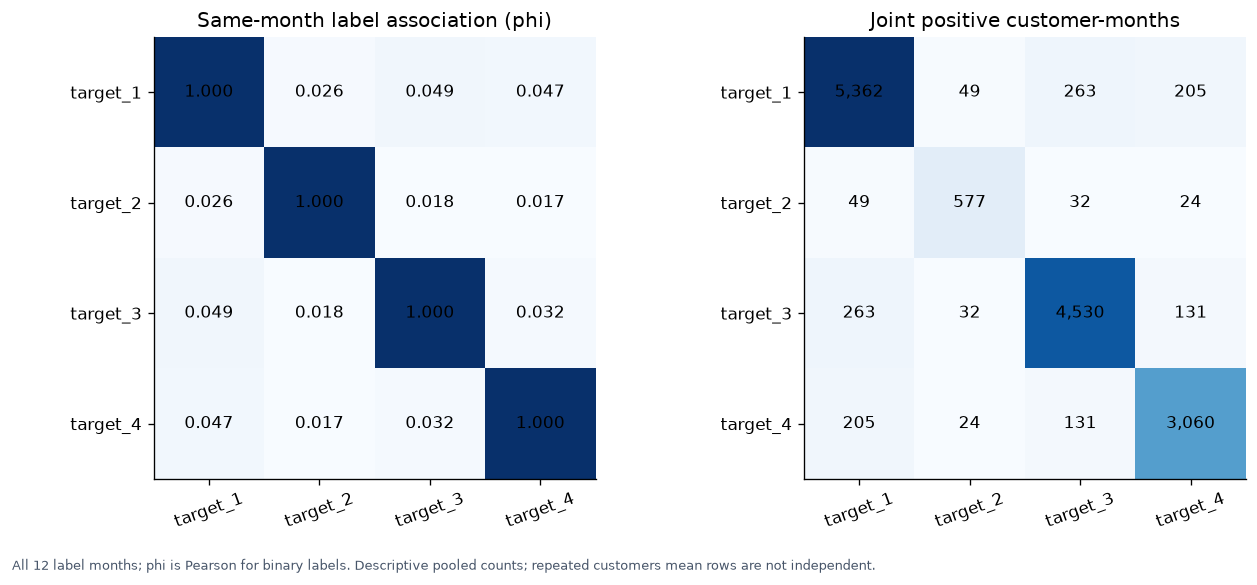

**outputs/relationships_moscow_20261118/edges_amount11_sum.csv** — 5 dòng đầu

,edge
0,4.474146e-02
1,2.740929e+06
2,1.710763e+07
3,7.441572e+07
4,1.377325e+13


**outputs/relationships_moscow_20261118/edges_dialog_events.csv** — 5 dòng đầu

,edge
0,1.0
1,3.0
2,5.0
3,108.0


**outputs/relationships_moscow_20261118/edges_geo_events.csv** — 5 dòng đầu

,edge
0,1.0
1,127.0
2,394.0
3,1007.0
4,37267.0


... (19 outputs left out)

,mon,a,b,n,rho
0,2022-02-01,trx_events,trx_days,100224,0.998292
1,2022-02-01,trx_events,trx_types,100224,0.833559
2,2022-02-01,trx_events,amount11_sum,87000,0.805453
3,2022-02-01,trx_events,amount11_mean,87000,0.220893
4,2022-02-01,trx_events,foreign_share,87000,0.121775


**outputs/relationships_moscow_20261118/trx_type_currency_shares.csv** — 5 dòng đầu

,event_type,Code 11,Missing,Other codes
0,1,0.999478,0.000002,0.000520
1,46,0.999992,0.000000,0.000008
2,40,0.997867,0.000008,0.002125
3,49,0.999993,0.000000,0.000007
4,11,1.000000,0.000000,0.000000


File kết quả khác: `outputs/relationships_moscow_20261118/REPORT.md`, `outputs/relationships_moscow_20261118/customer_snapshots.parquet`, `outputs/relationships_moscow_20261118/manifest.json`, `outputs/relationships_moscow_20261118/validation.json`

In [6]:
show_generated_results(__eda_started_ns, 'src/scripts/analyze_cross_table_relationships.py')